# 30 · Forward kinematics of the Panda: DH parameters by hand vs MuJoCo

In [1]:
import mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt

DH_A = [0, 0, 0, 0.0825, -0.0825, 0, 0.088]
DH_D = [0.333, 0, 0.316, 0, 0.384, 0, 0]
DH_ALPHA = [0, -np.pi / 2, np.pi / 2, np.pi / 2, -np.pi / 2, np.pi / 2, np.pi / 2]
FLANGE = 0.107

def mdh(a, alpha, d, theta):
    ca, sa, ct, st = np.cos(alpha), np.sin(alpha), np.cos(theta), np.sin(theta)
    return np.array([[ct, -st, 0, a], [st * ca, ct * ca, -sa, -d * sa], [st * sa, ct * sa, ca, d * ca], [0, 0, 0, 1]])

def fk_chain(q):
    T, frames = np.eye(4), [np.eye(4)]
    for i in range(7):
        T = T @ mdh(DH_A[i], DH_ALPHA[i], DH_D[i], q[i])
        frames.append(T.copy())
    frames.append(T @ np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 1, FLANGE], [0, 0, 0, 1]]))
    return frames

def draw_arm(ax, frames, color="k"):
    p = np.array([f[:3, 3] for f in frames])
    ax.plot(*p.T, "-o", color=color, ms=3)
    for f in frames[-1:]:
        for i, c in enumerate("rgb"):
            ax.quiver(*f[:3, 3], *(0.08 * f[:3, i]), color=c)

In [2]:
model = mm.load("franka_emika_panda"); data = mujoco.MjData(model)
rng = np.random.default_rng(0)
errs = []
for _ in range(1000):
    q = rng.uniform(model.jnt_range[:7, 0], model.jnt_range[:7, 1])
    data.qpos[:7] = q; mujoco.mj_kinematics(model, data)
    errs.append(np.abs(fk_chain(q)[-1][:3, 3] - data.body("hand").xpos).max())
print(f"1000 random configurations: max |DH flange - MuJoCo hand| = {max(errs):.2e} m")

1000 random configurations: max |DH flange - MuJoCo hand| = 8.88e-16 m


In [3]:
R_rel = fk_chain(q)[-1][:3, :3].T @ data.body("hand").xmat.reshape(3, 3)
print("MuJoCo hand frame relative to DH flange frame:\n", R_rel.round(3), "\n-> a fixed -45° rotation about z (the hand is mounted rotated)")

MuJoCo hand frame relative to DH flange frame:
 [[ 0.707  0.707 -0.   ]
 [-0.707  0.707 -0.   ]
 [ 0.    -0.     1.   ]] 
-> a fixed -45° rotation about z (the hand is mounted rotated)


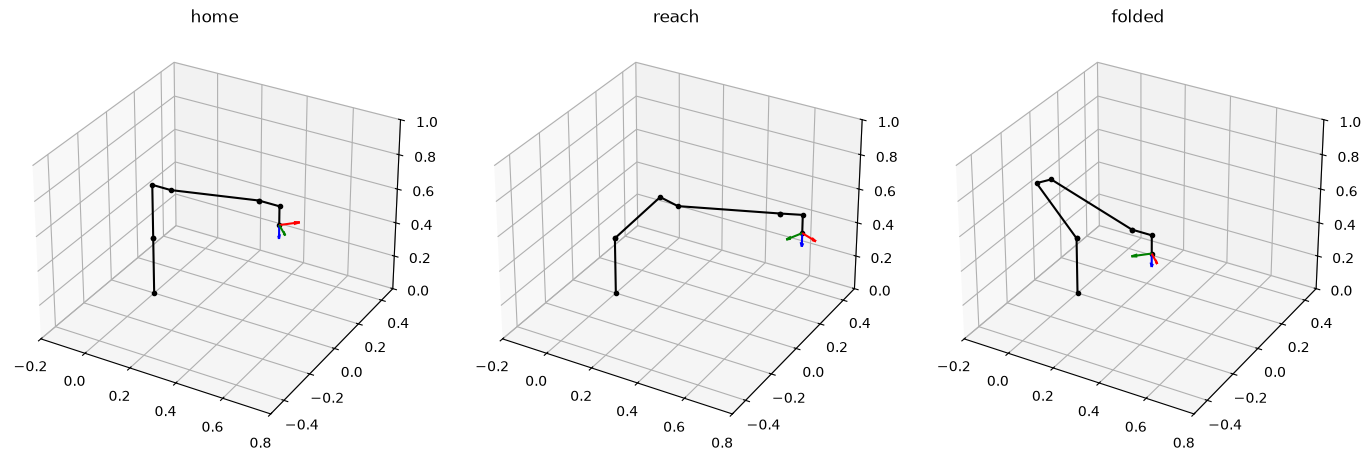

In [4]:
fig = plt.figure(figsize=(14, 4.5))
configs = {"home": [0, 0, 0, -1.571, 0, 1.571, -0.785], "reach": [0.4, 0.6, 0, -1.2, 0, 1.8, 0.785], "folded": [0, -0.6, 0, -2.8, 0, 2.2, 0.785]}
for k, (name, q) in enumerate(configs.items()):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    draw_arm(ax, fk_chain(np.array(q)))
    ax.set_xlim(-0.2, 0.8); ax.set_ylim(-0.5, 0.5); ax.set_zlim(0, 1.0); ax.set_title(name)
plt.tight_layout(); plt.show()

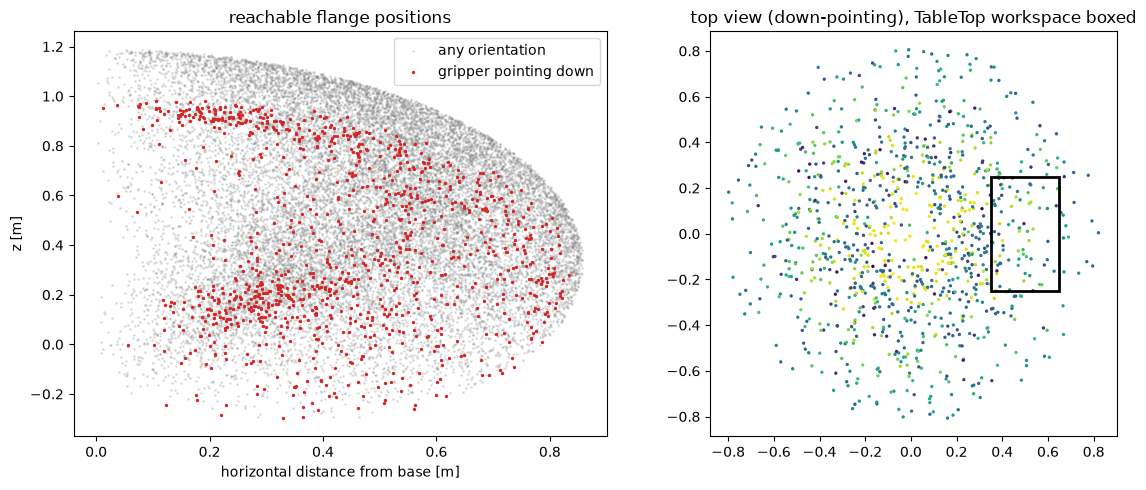

In [5]:
N = 20000
Q = rng.uniform(model.jnt_range[:7, 0], model.jnt_range[:7, 1], (N, 7))
P = np.array([fk_chain(q)[-1][:3, 3] for q in Q])
down = np.array([fk_chain(q)[-1][2, 2] < -0.9 for q in Q])
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(np.hypot(P[:, 0], P[:, 1]), P[:, 2], s=1, alpha=0.2, c="gray", label="any orientation")
ax[0].scatter(np.hypot(P[down, 0], P[down, 1]), P[down, 2], s=2, c="tab:red", label="gripper pointing down")
ax[0].set_xlabel("horizontal distance from base [m]"); ax[0].set_ylabel("z [m]"); ax[0].legend(); ax[0].set_title("reachable flange positions")
ax[1].scatter(P[down, 0], P[down, 1], s=2, c=P[down, 2], cmap="viridis"); ax[1].set_aspect("equal")
ax[1].add_patch(plt.Rectangle((0.35, -0.25), 0.3, 0.5, fill=False, ec="k", lw=2)); ax[1].set_title("top view (down-pointing), TableTop workspace boxed")
plt.tight_layout(); plt.show()